In [41]:
import scanpy as sc
score = {
    "Interleukin Signaling": "IL6, IL7, IL10, IL11, IL15, IL16, IL18, IL24, IL32, IL33, IL1R1, CSF3".split(", "),
    "Chemokine Signaling": "CCL4, CCL5, CCL13, CCL19, CCL21, CXCL1, CXCL2, CXCL3, CXCL5, CXCL6, CXCL8, CXCL9, CXCL10, CXCL11, CXCL13".split(", "),
    "Antigen Presentation": "CD74, HLA-DRA, HLA-DRB1, CTSS, CCL4".split(", "), 
    "Hedgehog Signaling": "BMP2, GAS1, GLI1, PSMB9, PSMB10, WNT2, WNT5A".split(", "),
    "NF-kappa B Signaling": "NFKB1, NFKB2, IKBKB, IKBKG, NFKBIA, RELA, RELB, TNF, BIRC3, CHUK, FASLG".split(", "), 
}
adata = sc.read("./h5ad/adata_fibroblast.h5ad")
sc.pp.normalize_total(adata, target_sum=1e6)
sc.pp.log1p(adata)
batch2effect = {
    "H-nS01":"H-poor",
    "Q-nS01":"Q-poor",
    "Q-nS02":"Q-poor",
    "H-nS08":"H-good",
    "Q-nS03":"Q-good",
    "Q-nS04":"Q-good",
    "H-nS03":"H-good",
    "H-nS06":"H-good",
    "H-nS07":"H-good",
    "H-nS09":"H-poor",
    "H-nS10":"H-poor"
}
adata.obs["effect"]=[batch2effect[b] for b in adata.obs["batch"]]
fibroblast1 = adata[adata.obs["celltype"]=="Inflammatory Fibroblast"]
fibroblast2 = adata[adata.obs["celltype"]=="Secretory-Translationally Active Fibroblast"]

/home/pyc2/miniconda3/envs/clickview/lib/python3.10/site-packages/scanpy/tools/_score_genes.py:165: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[score_name] = pd.Series(
/home/pyc2/miniconda3/envs/clickview/lib/python3.10/site-packages/scanpy/tools/_score_genes.py:165: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[score_name] = pd.Series(


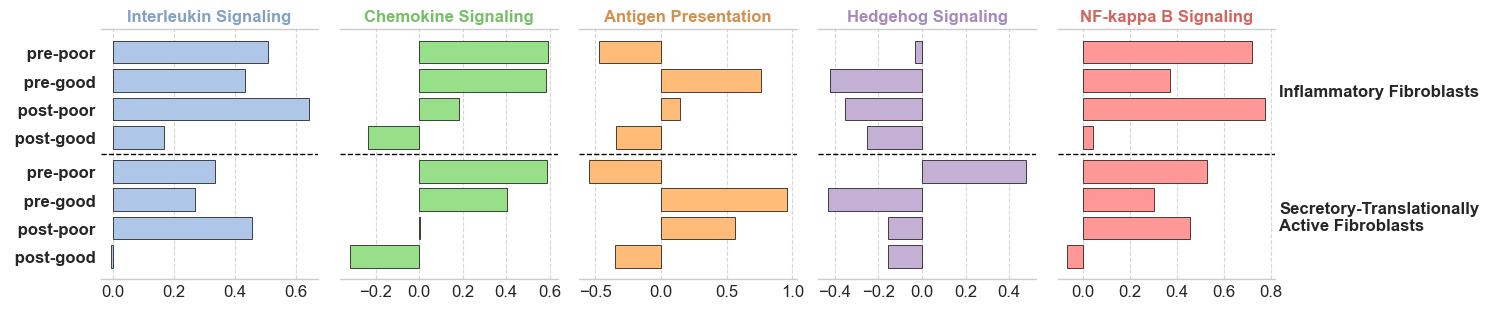

In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# 假设 score, fibroblast1, fibroblast2 已经定义并加载

def add_signature_scores(adata, signatures):
    for name, genes in signatures.items():
        genes_in_adata = [g for g in genes if g in adata.var_names]
        if len(genes_in_adata) == 0:
            print(f"Warning: No genes from '{name}' found in adata.")
            continue
        score_name = f"{name}"
        sc.tl.score_genes(adata, gene_list=genes_in_adata, score_name=score_name)

add_signature_scores(fibroblast1, score)
add_signature_scores(fibroblast2, score)

all_effects = set(fibroblast1.obs["effect"].unique()) | set(fibroblast2.obs["effect"].unique())
signature_names = list(score.keys())

rows = []

for source, adata_source in [("Inflammatory Fibroblasts", fibroblast1), ("Secretory-Translationally Active Fibroblasts", fibroblast2)]:
    for effect in all_effects:
        if effect in adata_source.obs["effect"].values:
            sub = adata_source[adata_source.obs["effect"] == effect]
            for sig in signature_names:
                col = f"{sig}"
                if col in sub.obs.columns:
                    mean_score = sub.obs[col].mean()
                    rows.append({
                        "source": source,
                        "effect": effect,
                        "signature": sig,
                        "score": mean_score
                    })

df = pd.DataFrame(rows)
df["group_label"] = df["source"] + " | " + df["effect"]

# 获取所有唯一组合（保持顺序）
group_labels = sorted(df["group_label"].unique())
n_groups = len(group_labels)
n_signatures = len(signature_names)

fig, axes = plt.subplots(1, n_signatures, figsize=(3 * n_signatures, 0.4 * n_groups), sharey=True)

color_map = ["#aec7e8","#98df8a","#ffbb78","#c5b0d5","#ff9896"]
darkened_color_map = [
    "#84a0c4",  # 深蓝 (从 #aec7e8 加深)
    "#76bf66",  # 深绿 (从 #98df8a 加深)
    "#d38f4c",  # 深橙 (从 #ffbb78 加深)
    "#a58ab9",  # 深紫 (从 #c5b0d5 加深)
    "#d3655f"   # 深红 (从 #ff9896 加深)
]

for i, sig in enumerate(signature_names):
    ax = axes[i] if n_signatures > 1 else axes
    
    sub_df = df[df["signature"] == sig]
    
    scores = []
    colors_list = []
    for label in group_labels:
        row = sub_df[sub_df["group_label"] == label]
        if not row.empty:
            scores.append(row["score"].values[0])
            src = row["source"].values[0]
            colors_list.append(color_map[i])
        else:
            scores.append(0)
            colors_list.append("lightgray")
    
    y_pos = np.arange(n_groups)
    y_pos = [y+0.2 if i>=len(y_pos)//2 else y for i,y in enumerate(y_pos)]
    y_pos = y_pos[-4:] + y_pos[:4]
    
    bars = ax.barh(y_pos, scores, color=colors_list, edgecolor='k', linewidth=0.5)

    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.set_yticks(y_pos)
    ax.tick_params(axis='y', which='both', length=0)
    ax.set_yticklabels([l.split("|")[1].replace("H","post").replace("Q","pre") for l in group_labels],fontweight='bold',fontsize=12)
    ax.set_title(sig,fontweight='bold',fontsize = 12,color=darkened_color_map[i])
    ax.set_xticks([[0.0,0.2,0.4,0.6],[-0.2,0.0,0.2,0.4,0.6],[-0.5,0.0,0.5,1.0],[-0.4,-0.2,0.0,0.2,0.4],[0.0,0.2,0.4,0.6,0.8]][i])
    ax.tick_params(axis='x', labelsize=12)
    #ax.tick_params(axis='x', rotation=-90)
    #for label in ax.get_xticklabels():
    #    label.set_weight('bold')
    #ax.set_xticklabels(ax.get_xticks(),fontweight='bold')
    ax.grid(axis="y",alpha=0.0)
    ax.grid(axis='x', linestyle='--', alpha=0.8)
    ax.axhline(y=3.6, color='black', linestyle='--', linewidth=1)

plt.tight_layout()
last_ax = axes[-1] if n_signatures > 1 else axes

# 获取 x 轴的最大值（用于定位文字的 x 位置）
x_max = last_ax.get_xlim()[1]

# 可选：稍微往右偏移一点，避免和条形/网格线重叠
x_text = x_max * 1.02  # 往右 2%

# 添加上半部分标签（虚线之上）
last_ax.text(x_text, 0.75, 'Inflammatory Fibroblasts', 
             va='center', ha='left', 
             fontsize=12, fontweight='bold',
             transform=last_ax.get_xaxis_transform())  # 注意这里！

# 添加下半部分标签（虚线之下）
last_ax.text(x_text, 0.25, 'Secretory-Translationally\nActive Fibroblasts', 
             va='center', ha='left', 
             fontsize=12, fontweight='bold',
             transform=last_ax.get_xaxis_transform())
plt.tight_layout()
plt.show()